Question 3: Sales Visualization

Using the cleaned dataset from Question 1 ('sales_data.csv'), create the following visualizations:

1. Create a line plot showing daily sales trends over time
   - Include a 7-day moving average line

2. Create a bar plot showing:
   - Total sales by category
   - Include error bars representing standard deviation

3. Create a scatter plot showing:
   - Relationship between quantity and price
   - Color points by category
   - Add a trend line

Requirements:
- Use appropriate labels and titles
- Include a legend where necessary
- Use a consistent color scheme
- Save all plots as PNG files

In [48]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from datetime import date

In [45]:
# first, let's load the dataset 

sales_df = pd.read_csv('../data/curated/sales_data.csv')
sales_df['sale_date_date'] = sales_df['sale_date'].apply(lambda x: date(*[int(d) for d in x.split('-')]))

sales_df_grouped = sales_df.groupby("sale_date_date")[['price']].sum()

In [59]:
# 7-day moving average

moving_avg = np.convolve(sales_df_grouped['price'], np.ones(7), 'valid')/7

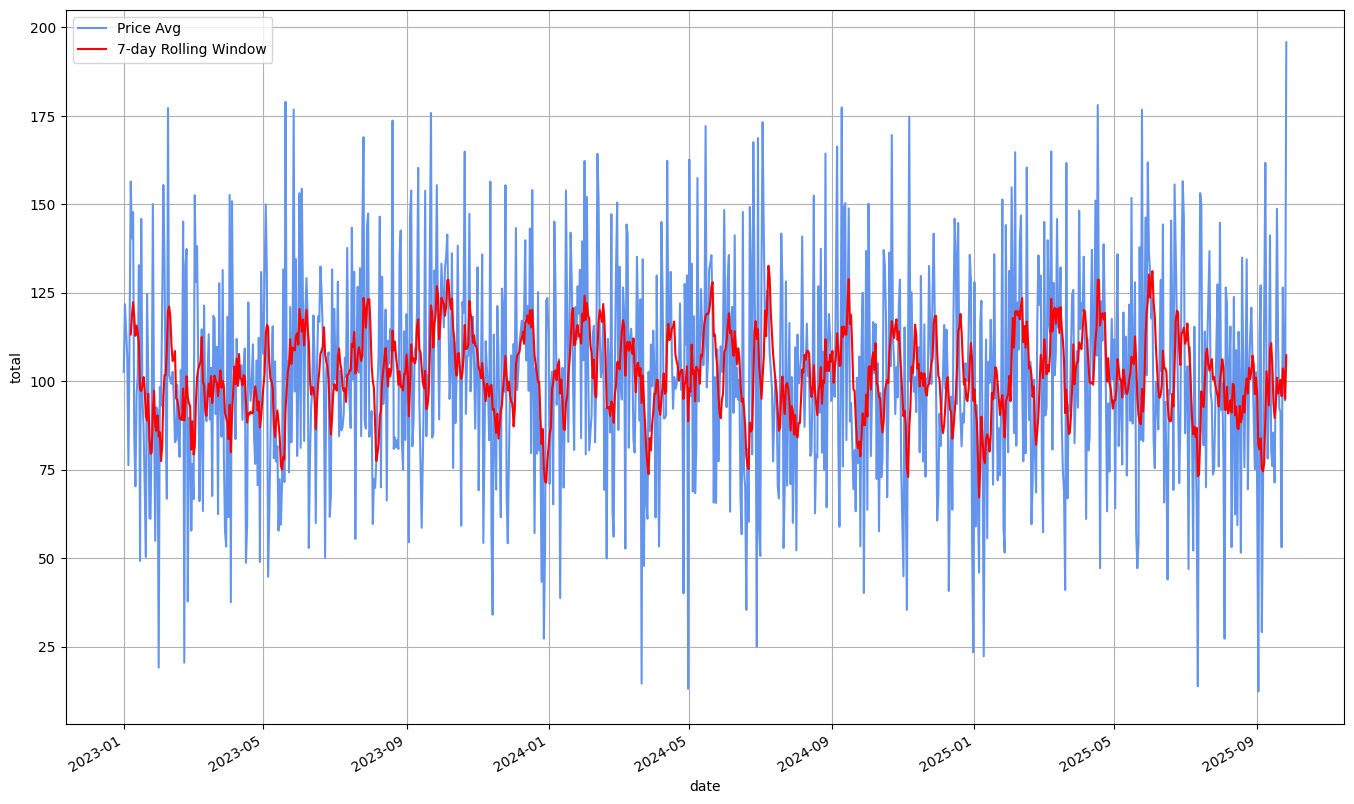

In [127]:
fig, ax = plt.subplots()
fig.set_size_inches(16.5, 10.5)
ax.plot(sales_df['sale_date_date'], sales_df['price'], color='cornflowerblue', label='Price Avg')
ax.plot(sales_df['sale_date_date'][6:], moving_avg, color='red',  linewidth=1.5, label='7-day Rolling Window')

ax.set(xlabel='date', ylabel='total')
ax.xaxis_date()
fig.autofmt_xdate()
plt.grid()
plt.legend(loc='best')
fig.savefig("price_avg_with_rolling_window.png")
plt.show()

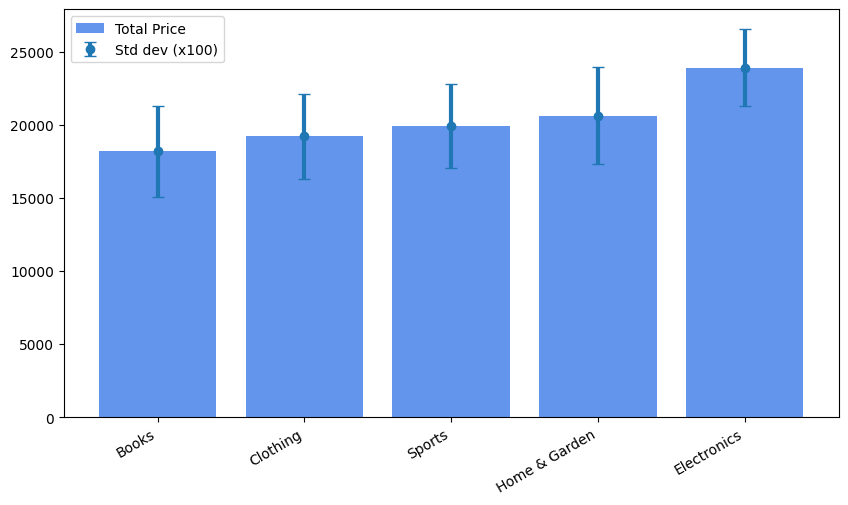

In [165]:
fig, ax = plt.subplots()

# I'll manually calculate the total sales by cat. because I want to sort the bars
data = sales_df.groupby('category')[['price']].sum().sort_values(['price'])
stdev_per_category = sales_df.groupby('category')[['price'][0]].describe()['std']
data['stddev'] = stdev_per_category
data = data.sort_values('price').reset_index()

ax.bar(data['category'], height=data['price'], color='cornflowerblue', label='Total Price')

# I kinda dislike this, but multiplying the yerr by 100 is the only way to make the lines visible
ax.errorbar(data['category'], data['price'], yerr=data['stddev']*100,  fmt='o', 
            linewidth=3, capsize=4, label='Std dev (x100)')

fig.autofmt_xdate()
fig.set_size_inches(10, 6)
plt.legend(loc='best')
fig.savefig("sales_per_category.png")
plt.show()

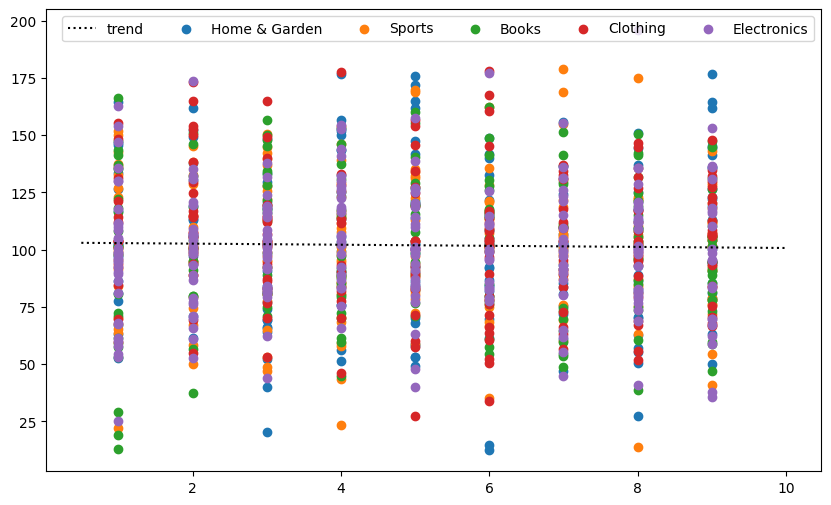

In [167]:
fig, ax = plt.subplots()
fig.set_size_inches(10, 6)
categories = sales_df['category'].unique()
for category in categories:
    ax.scatter(
        sales_df[sales_df['category'] == category]['quantity'],
        sales_df[sales_df['category'] == category]['price'],
        label=category
    )
    
# for the trend line we need to perform linear regression on the values
alpha, b = np.polyfit(sales_df['quantity'], sales_df['price'], 1)
line = np.linspace(.5, 10, num=100)
plt.plot(line, alpha*line + b, color='black', linestyle='dotted', label='trend')
plt.legend(loc='best', ncol=len(categories) + 1)
fig.savefig("quantity_x_price_with_trend.png")
plt.show()